In [ ]:
# JulioPrajaSarbunan_202431152
# Langkah 1
!pip install requests beautifulsoup4 pandas
import requests, csv
import pandas as pd
from bs4 import BeautifulSoup

In [ ]:
# Langkah 2, 202431152_JulioPraja
df = pd.read_csv('coffee_analysis.csv')
print(df.shape)   # untuk laporan: baris x kolom
df

(2095, 12)


,name,roaster,roast,loc_country,origin_1,origin_2,100g_USD,rating,review_date,desc_1,desc_2,desc_3
0,“Sweety” Espresso Blend,A.R.C.,Medium-Light,Hong Kong,Panama,Ethiopia,14.32,95,November 2017,"Evaluated as espresso. Sweet-toned, deeply ric...",An espresso blend comprised of coffees from Pa...,A radiant espresso blend that shines equally i...
1,Flora Blend Espresso,A.R.C.,Medium-Light,Hong Kong,Africa,Asia Pacific,9.05,94,November 2017,"Evaluated as espresso. Sweetly tart, floral-to...",An espresso blend comprised of coffees from Af...,"A floral-driven straight shot, amplified with ..."
2,Ethiopia Shakiso Mormora,Revel Coffee,Medium-Light,United States,Guji Zone,Southern Ethiopia,4.70,92,November 2017,"Crisply sweet, cocoa-toned. Lemon blossom, roa...",This coffee tied for the third-highest rating ...,"A gently spice-toned, floral- driven wet-proce..."
3,Ethiopia Suke Quto,Roast House,Medium-Light,United States,Guji Zone,Oromia Region,4.19,92,November 2017,"Delicate, sweetly spice-toned. Pink peppercorn...",This coffee tied for the third-highest rating ...,Lavender-like flowers and hints of zesty pink ...
4,Ethiopia Gedeb Halo Beriti,Big Creek Coffee Roasters,Medium,United States,Gedeb District,Gedeo Zone,4.85,94,November 2017,"Deeply sweet, subtly pungent. Honey, pear, tan...",Southern Ethiopia coffees like this one are pr...,A deeply and generously lush cup saved from se...
...,...,...,...,...,...,...,...,...,...,...,...,...
2090,Finca Patzibir,El Gran Cafe,Medium-Light,Guatemala,Lake Atitlán Growing Region,Guatemala,4.70,92,November 2022,"Crisply sweet, nut-toned. Almond brittle, pie ...",Produced by Andres Fahsen of Finca Patzibar en...,"A quietly confident, sweetly nut-toned Guatema..."
2091,Proyecto Aurora,El Gran Cafe,Medium-Light,Guatemala,Antigua Growing Region,Guatemala,2.94,93,November 2022,"Chocolaty, floral-framed. Cocoa nib, honeysuck...",Produced at Beneficio La Esperanza from trees ...,"A deeply floral, richly chocolaty Guatemala cu..."
2092,Finca El Potrero,El Gran Cafe,Medium-Light,Guatemala,Antigua Growing Region,Guatemala,2.94,93,November 2022,"High-toned, enticingly sweet. Black cherry, na...",Produced by Josué Morales of Finca El Potrero...,"A bright, balanced, juicy Guatemala cup driven..."
2093,Chacayá Santiago Atitlán,El Gran Cafe,Medium-Light,Guatemala,Lake Atitlán Growing Region,Guatemala,4.70,93,November 2022,"Vibrantly sweet, subtly nuanced. Apricot, dar...",Produced by smallholding farmers of Asociación...,"Balanced, bright, invigoratingly crisp, with t..."


In [ ]:
# Langkah 3: informasi data (tipe kolom, jumlah non-null)
# 202431152_JulioPraja
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2095 entries, 0 to 2094
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name         2095 non-null   object 
 1   roaster      2095 non-null   object 
 2   roast        2080 non-null   object 
 3   loc_country  2095 non-null   object 
 4   origin_1     2095 non-null   object 
 5   origin_2     2095 non-null   object 
 6   100g_USD     2095 non-null   float64
 7   rating       2095 non-null   int64  
 8   review_date  2095 non-null   object 
 9   desc_1       2095 non-null   object 
 10  desc_2       2095 non-null   object 
 11  desc_3       2093 non-null   object 
dtypes: float64(1), int64(1), object(10)
memory usage: 196.5+ KB


In [ ]:
# Langkah 4: statistik deskriptif kolom angka
# 202431152_JulioPraja
df.describe()

,100g_USD,rating
count,2095.000000,2095.000000
mean,9.323313,93.114081
std,11.430659,1.563024
min,0.120000,84.000000
25%,4.930000,92.000000
50%,5.860000,93.000000
75%,8.785000,94.000000
max,132.280000,98.000000


In [ ]:
# Langkah 5: jumlah data kosong per kolom
# 202431152_JulioPraja
df.isna().sum()

,0
name,0
roaster,0
roast,15
loc_country,0
origin_1,0
origin_2,0
100g_USD,0
rating,0
review_date,0
desc_1,0


In [ ]:
# Langkah 6: isi unik tiap kolom kategorik
# 202431152_JulioPraja
kolom_kat = df.select_dtypes(include='object').columns
for k in kolom_kat:
    print(k, '->', df[k].unique())

name -> ['“Sweety” Espresso Blend' 'Flora Blend Espresso'
 'Ethiopia Shakiso Mormora' ... 'Finca El Potrero'
 'Chacayá Santiago Atitlán' 'Espresso No. 3']
roaster -> ['A.R.C.' 'Revel Coffee' 'Roast House' 'Big Creek Coffee Roasters'
 'Red Rooster Coffee Roaster' "Willoughby's Coffee & Tea"
 'Black Oak Coffee Roasters' 'Wonderstate Coffee' 'Reunion Island Coffee'
 "PT's Coffee Roasting" 'Kakalove Cafe' 'Level Ground Trading'
 'Old Soul Co.' 'Bootstrap Coffee Roasters' 'Paradise Roasters'
 'Hula Daddy Kona Coffee' 'Jackrabbit Java' 'Propeller Coffee'
 'Chocolate Fish Coffee Roasters' 'Caffe Luxxe' 'Espresso Republic'
 'Lexington Coffee Roasters' 'Noble Coffee Roasting' 'Red E Café'
 "Ben's Beans" 'Speckled Ax' 'Fumi Coffee' 'Good Folks Coffee'
 'Flight Coffee Co.' 'Dragonfly Coffee Roasters' 'OQ Coffee Co.'
 'Green Stone Coffee' 'Bird Rock Coffee Roasters' 'Equator Coffees & Teas'
 'JBC Coffee Roasters' 'Klatch Coffee' 'Campos Coffee'
 "Ka'u Specialty Coffee" 'Simon Hsieh’s Aroma Roast C

In [ ]:
# Langkah 7: isi data kosong, hasil DISIMPAN kembali ke df
# 202431152_JulioPraja
for k in kolom_kat:
    df[k] = df[k].fillna(df[k].mode()[0])      # modus untuk kategorik

kolom_num = df.select_dtypes(include='number').columns
for k in kolom_num:
    df[k] = df[k].fillna(df[k].mean())         # mean untuk angka

print(df.isna().sum())   # harus 0 semua

name           0
roaster        0
roast          0
loc_country    0
origin_1       0
origin_2       0
100g_USD       0
rating         0
review_date    0
desc_1         0
desc_2         0
desc_3         0
dtype: int64


In [ ]:
# Langkah 8: hitung duplikat
# 202431152_JulioPraja
print(df.duplicated().sum())

0


In [ ]:
# Langkah 9: hapus duplikat dan cek hasil
# 202431152_JulioPraja
df = df.drop_duplicates()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2095 entries, 0 to 2094
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name         2095 non-null   object 
 1   roaster      2095 non-null   object 
 2   roast        2095 non-null   object 
 3   loc_country  2095 non-null   object 
 4   origin_1     2095 non-null   object 
 5   origin_2     2095 non-null   object 
 6   100g_USD     2095 non-null   float64
 7   rating       2095 non-null   int64  
 8   review_date  2095 non-null   object 
 9   desc_1       2095 non-null   object 
 10  desc_2       2095 non-null   object 
 11  desc_3       2095 non-null   object 
dtypes: float64(1), int64(1), object(10)
memory usage: 196.5+ KB


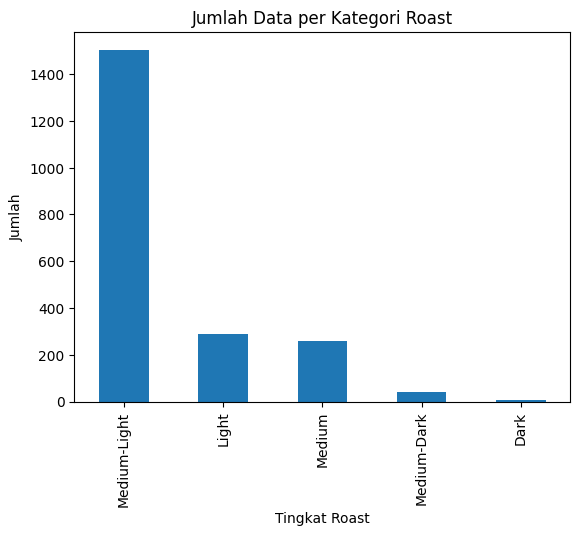

In [ ]:
# Langkah 10: grafik batang jumlah tiap kategori
df['kolom_kategori'].value_counts().plot(kind='bar')
plt.title('Jumlah Data per Kategori')
plt.xlabel('Kategori')
plt.ylabel('Jumlah')
plt.show()